# Test code for symmetries and accuracy of auto- & cross-correlations

In [27]:
# Tensor Cubic E1 normalized Matrices
import numpy as np
import os
import matplotlib.pyplot as plt
l_max= 10
directory = 'runs/E6_LAx_0.60_LBy_0.50_LCz_0.50_alphax_0.50_alphay_0.50_alphaz_0.50_x_0.00_y_0.50_z_0.00_l_max_10_accuracy_99_percent/'
c_full = np.load(directory + 'full_corr_matrix_1_l_2_10_lp_2_10.npy')

a_tol = 1e-14
type = 3

## $C^{XY}_{\ell m, \ell' -m'} = (-1)^{m+m'} C^{XY *}_{\ell -m, \ell' m'}$

In [14]:
shortle = np.array([1, -1])
for l in range(2, l_max + 1):
    for l_p in range(2, l_max+1):
        for m in range(-l, l + 1):
          lm_index_new = l * (l+1) + m - 4 # l**2 + l +m - l_min**2
          lm_index_cal = l * (l+1) - m - 4
          for m_p in range(-l_p, 0):
            lm_p_index_new = l_p * (l_p+1) + m_p  - 4
            lm_p_index_cal = l_p * (l_p+1) - m_p  - 4
            if c_full[type, lm_index_new, lm_p_index_new] - shortle[(m+m_p)%2] * np.conjugate(c_full[type, lm_index_cal, lm_p_index_cal]) > a_tol:
               print(f"ell m, ell' m'= {l, m, l_p, m_p}")
               print(c_full[type, lm_index_new, lm_p_index_new])
               print(c_full[type, lm_index_cal, lm_p_index_cal])

## $C^{XX}_{\ell m, \ell' m'} = C^{XX *}_{\ell' m', \ell m}$ only for auto-correlations

In [28]:
shortle = np.array([1, -1])
for l in range(2, l_max + 1):
    for l_p in range(l, l_max+1):
        for m in range(-l, l + 1):
          lm_index= l * (l+1) + m - 4 # l**2 + l +m - l_min**2
          for m_p in range(-l_p, l_p + 1):
            lm_p_index = l_p * (l_p+1) + m_p  - 4
            if c_full[type, lm_index, lm_p_index] - np.conjugate(c_full[type, lm_p_index, lm_index]) > a_tol:
               print(f"ell m, ell' m'= {l, m, l_p, m_p}")
               print(c_full[type, lm_index, lm_p_index])
               print(c_full[type, lm_p_index, lm_index])

ell m, ell' m'= (2, -2, 4, -4)
(-0.011856359531981131+3.7917003075941125e-19j)
(-0.01221600069414674+6.488804360904931e-19j)
ell m, ell' m'= (2, -2, 4, -2)
(0.016823893038964123-6.909903446532434e-20j)
(0.014981149596222374-2.3883382578081817e-19j)
ell m, ell' m'= (2, -2, 4, 2)
(0.003916415088096001-1.725350516707509e-19j)
(0.003833550252913007+9.41364728270368e-19j)
ell m, ell' m'= (2, -1, 4, -3)
(0.009104049864110014-6.333399547774296e-19j)
(0.008979679423221436-7.215671671755443e-19j)
ell m, ell' m'= (2, -1, 4, -1)
(-0.008304649816110937-2.23728747675455e-19j)
(-0.010317183415743758+1.6928223743856147e-19j)
ell m, ell' m'= (2, 0, 4, -4)
(0.005554135714347716-4.982646755706005e-20j)
(0.002739562596503741-3.1201911568545247e-18j)
ell m, ell' m'= (2, 0, 4, -2)
(-0.00453214314840018+3.600385440988653e-20j)
(-0.005073017762724615+1.0786833709953714e-18j)
ell m, ell' m'= (2, 0, 4, 0)
(-0.011371384495548992+5.807851331659717e-35j)
(-0.01172961004991041+4.849027189437478e-34j)
ell m, ell' m

## $C^{XY}_{\ell -m, \ell' -m'} = (-1)^{m+m'} C^{XY *}_{\ell m, \ell' m'}$

In [4]:
shortle = np.array([1, -1])
for l in range(2, l_max + 1):
    for l_p in range(2, l_max+1):
        for m in range(-l, l + 1):
          lm_index_new = l * (l+1) + m - 4 # l**2 + l +m - l_min**2
          lm_index_cal = l * (l+1) - m - 4
          for m_p in range(-l_p, l_p + 1):
            lm_p_index_new = l_p * (l_p+1) + m_p  - 4
            lm_p_index_cal = l_p * (l_p+1) - m_p  - 4
            if c_full[type, lm_index_new, lm_p_index_new] - shortle[(m+m_p)%2] * np.conjugate(c_full[type, lm_index_cal, lm_p_index_cal]) > a_tol:
               print(f"ell m, ell' m'= {l, m, l_p, m_p}")
               print(c_full[type, lm_index_new, lm_p_index_new])
               print(c_full[type, lm_index_cal, lm_p_index_cal])

# Comparing the diagonal elements to covering space

In [6]:
import camb 

pars = camb.CAMBparams()
pars.set_cosmology(H0=67.5, ombh2=0.022, omch2=0.122, mnu=0.06, omk=0, tau=0.06)
pars.InitPower.set_params(As=2e-9, ns=0.965, r=0.1)
pars.set_for_lmax(l_max)
pars.WantTensors = True
# More accurate transfer functions. Takes longer time to run
pars.set_accuracy(AccuracyBoost = 2, lAccuracyBoost = 2, lSampleBoost = 50)
pars.Accuracy.IntkAccuracyBoost = 2
pars.Accuracy.SourcekAccuracyBoost = 2

# Get the CAMB functions and save them
data = camb.get_transfer_functions(pars)
results = camb.get_results(pars)
powers = results.get_cmb_power_spectra(pars, raw_cl= True, CMB_unit='muK')['tensor']

In [7]:
def get_c_l_from_c_lmlpmp(c_lmlpmp, l_max):
    c_l = np.zeros(l_max+1, dtype=np.complex128)

    for l in range(2, l_max+1):
        for m in range(-l, l+1):
            lm_id = l * (l+1) + m - 2*2
            c_l[l] += c_lmlpmp[lm_id, lm_id]
        c_l[l] /= 2*l + 1
    return np.real(c_l)

c_l = np.zeros((4, l_max+1), dtype=np.complex128)
c_l[0] = get_c_l_from_c_lmlpmp(c_full[0], l_max)
c_l[1] = get_c_l_from_c_lmlpmp(c_full[1], l_max)
c_l[2] = get_c_l_from_c_lmlpmp(c_full[2], l_max)
c_l[3] = get_c_l_from_c_lmlpmp(c_full[3], l_max)

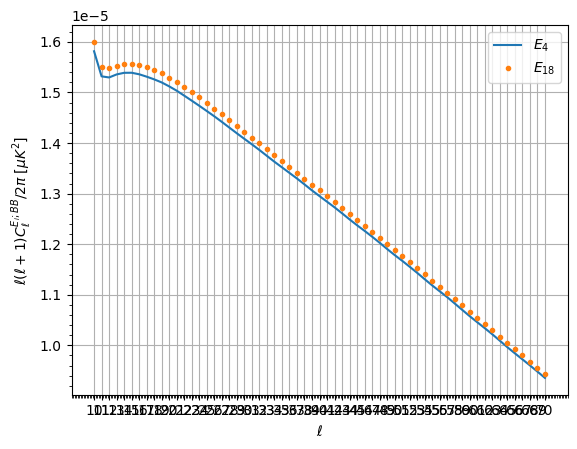

In [11]:
fig, ax = plt.subplots()
type = 1
l_start = 10
ell_list = np.arange(l_start, l_max+1)
d = ell_list * (ell_list + 1) / 2 / np.pi
ax.plot(ell_list, c_l[type, l_start: l_max+1].real,  label = '$E_4$')
ax.plot(ell_list, powers[l_start: l_max+1, type], 'o' ,markersize = 3, label = '$E_{18}$')

# ax.plot(ell_list[:15], np.abs(c_l_BE_60[15]) * ell_list[:15] * (ell_list[:15] + 1) / 2 / np.pi, 'black', label = '$E_3$')

#ax.plot(powers[:101, 2], 'b', label = '$E_{18}$')
# ax.set_title('$EB$ correlation for cubic $E_3$ topology')
# ax.set_xlim([2, 80])
ax.set_xticks(ell_list)
ax.set_xlabel('$\\ell$')
ax.set_ylabel('$\\ell (\\ell + 1)C^{E_i; BB}_{\\ell} / 2\\pi$ [$\\mu K^2$]')
#ax.set_xscale('log')
#ax.set_yscale('log')
ax.minorticks_on()
# ax.xaxis.set_minor_locator(1)
ax.legend()
ax.grid(True)